# Recurrent Neural Networks

In this learning module, we will illustrate two examples: 
- a traffic volume forecasting model and 
- a language model
  
Students are expected to review the traffic volume prediction problem. The language model is optional, provided for students who are interested in language models.

## 1. Traffic-volume forecasting

This notebook uses the UCI Metro Interstate Traffic Volume dataset, which contains hourly westbound I-94 traffic volume near Minneapolis–St Paul together with weather and holiday information from 2012–2018.

**Learning objectives**

By the end of the notebook, students should be able to:

1. Convert a time series into supervised sequence examples.
2. Explain the tensor shapes expected by PyTorch recurrent layers.
3. Implement a one-layer vanilla RNN for regression.
4. Extend the model to a stacked/deep RNN.
5. Replace the recurrent cell with LSTM and GRU cells.
6. Explain how a BiRNN reads the same history in two directions to predict the next hour.
7. Train all models with the same pipeline and compare validation/test performance.

**Forecasting task**

Use the most recent 24 observed hours to predict traffic volume at hour $t$.

For a lookback length $\tau=24$, one training example is

$$
\mathbf{X}^{(t)} = [\mathbf{x}_{t-\tau},\ldots,\mathbf{x}_{t-1}],
$$

with target

$$
y^{(t)} = v_{t},
$$

where $v_{t}$ is the traffic volume in the next hour.

The recurrent network receives a tensor with shape

$$
(\text{batch size},\ \text{sequence length},\ \text{number of features}).
$$

### 1.1 Data preparation

#### 1.1.1 Import dependencies

In [1]:
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 555
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")       # NVIDIA GPU
#elif torch.backends.mps.is_available():
#    DEVICE = torch.device("mps")        # Apple Silicon GPU
else:
    DEVICE = torch.device("cpu")
    torch.set_num_threads(2)

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

PyTorch: 2.13.0
Device: cpu


#### 1.1.2 Use the local UCI dataset

John Hogue (2019), *Metro Interstate Traffic Volume*, UCI Machine Learning Repository. DOI: 10.24432/C5X60B.  <https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume>


The dataset is `Metro_Interstate_Traffic_Volume.csv`, provided through the course repository. Save it in the `Data` subfolder. No download is needed when running this notebook.

In [2]:
# Students can change this to where the data is stored
DATA_PATH = "Data/Metro_Interstate_Traffic_Volume.csv" 

#### 1.1.3 Inspect the raw data

The target is `traffic_volume`. We will begin with a compact feature set so that the architecture, not feature engineering, stays central.

In [3]:
# since the data is time series data, we will sort the data by date_time and reset the index
raw = pd.read_csv(DATA_PATH, parse_dates=["date_time"]) 
raw = raw.sort_values("date_time").reset_index(drop=True)

# Let's check the shape of the data and display the first few rows to develop an initial understanding of the dataset.
print("Rows and columns:", raw.shape)
display(raw.head())

Rows and columns: (48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


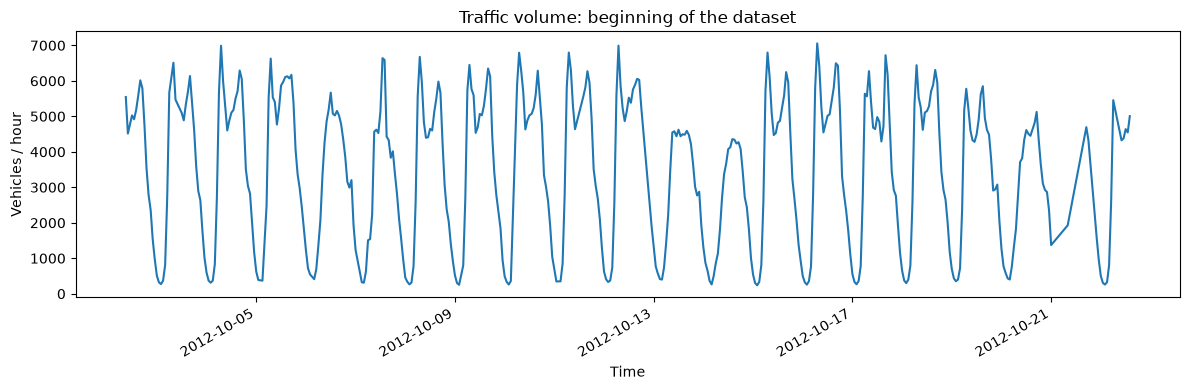

In [4]:
# Visualize the first three weeks to inspect short-term traffic patterns.
# The first 504 rows correspond to three weeks of hourly data.
sample = raw.iloc[:504]
ax = sample.plot(x="date_time", y="traffic_volume", figsize=(12, 4), legend=False)
ax.set_title("Traffic volume: beginning of the dataset")
ax.set_xlabel("Time")
ax.set_ylabel("Vehicles / hour")
plt.tight_layout()
plt.show()

**Keep the hourly timeline honest**

Combine duplicate timestamps and put the data on an hourly grid. 
Some hours are missing. Keep only examples whose 24-hour history and next-hour target are observed.
Do not invent traffic values by interpolation. 
We will report how many examples remain.

In [5]:
# One row per hour. Leave missing traffic values as NaN.
hourly = raw.groupby("date_time")[["traffic_volume"]].mean().asfreq("h")
print("Missing hours:", hourly["traffic_volume"].isna().sum())
display(hourly.head())

Missing hours: 11976


,traffic_volume
date_time,
2012-10-02 09:00:00,5545.0
2012-10-02 10:00:00,4516.0
2012-10-02 11:00:00,4767.0
2012-10-02 12:00:00,5026.0
2012-10-02 13:00:00,4918.0


#### 1.1.4 Traffic and calendar inputs

Use six features per hour: 
- traffic volume, 
- sine/cosine of hour, 
- sine/cosine of weekday, and 
- a weekend indicator. 
The calendar features let a short-window model learn typical daily and weekly patterns.

Cyclic encoding uses $\sin(2\pi z/P)$ and $\cos(2\pi z/P)$.

**Why exclude environmental inputs?** A controlled extension added temperature, rain, snow, and cloud-cover history to the same Deep RNN. Validation RMSE improved only from 251.79 to 249.97 vehicles/hour (about 0.7%), test RMSE improved by about 0.4%, and test MAE became slightly worse. This small, inconsistent gain does not justify extra preprocessing in the core architecture lesson, so the finalized teaching model keeps the compact traffic-and-calendar inputs.

In [6]:
df = hourly.copy()
hour = df.index.hour
dow = df.index.dayofweek
df["hour_sin"] = np.sin(2 * np.pi * hour / 24)
df["hour_cos"] = np.cos(2 * np.pi * hour / 24)
df["dow_sin"] = np.sin(2 * np.pi * dow / 7)
df["dow_cos"] = np.cos(2 * np.pi * dow / 7)
df["weekend"] = (dow >= 5).astype(float) 
FEATURES = ["traffic_volume", "hour_sin", "hour_cos", "dow_sin", "dow_cos", "weekend"]
TARGET = "traffic_volume"
print("Features:", FEATURES)

Features: ['traffic_volume', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'weekend']


#### 1.1.5 Chronological train / validation / test split

For time series, a random split can leak information from the future into the training set. We therefore keep chronological order:

- first 70%: training;
- next 15%: validation;
- final 15%: test.

**Important:** means and standard deviations are estimated from the training period only. We apply those fixed training statistics to validation and test data. We never fit preprocessing on either held-out split.

In [7]:
n = len(df)
train_end = int(0.70 * n)
val_end = int(0.85 * n)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

print("Train:", train_df.index.min(), "to", train_df.index.max(), len(train_df))
print("Valid:", val_df.index.min(), "to", val_df.index.max(), len(val_df))
print("Test :", test_df.index.min(), "to", test_df.index.max(), len(test_df))

Train: 2012-10-02 09:00:00 to 2016-12-13 01:00:00 36785
Valid: 2016-12-13 02:00:00 to 2017-11-06 12:00:00 7883
Test : 2017-11-06 13:00:00 to 2018-09-30 23:00:00 7883


In [8]:
# Learn scaling statistics from training data only.
feature_mean = train_df[FEATURES].mean()
feature_std = train_df[FEATURES].std().replace(0, 1)

target_mean = feature_mean[TARGET]
target_std = feature_std[TARGET]

# Apply the same scaling to every split.
for split in (train_df, val_df, test_df):
    split["target_raw"] = split[TARGET].copy()
    split["target_scaled"] = (split["target_raw"] - target_mean) / target_std
    split[FEATURES] = (split[FEATURES] - feature_mean) / feature_std

**Question:** Why do we normalize using training data only?

Normalization keeps differently scaled inputs numerically manageable. Using only training statistics prevents information from validation or test periods from influencing model preparation.

#### 1.1.6 Turn the series into examples

Use `LOOKBACK = 24`: each input has shape $(24,6)$ and the target is the next hour's standardized traffic volume. At target index `t`, use `t-24:t`, which excludes the target.

Keep only complete, observed histories and targets. All models and baselines use the same examples. Windows stay inside their chronological split.

The loop takes 24 input rows and the next target. It skips examples containing missing values. `TensorDataset` stores these input–target pairs for the data loader. The returned target rows retain timestamps and raw traffic for evaluation.

In [9]:
LOOKBACK = 24

def make_sequences(frame):
    features = frame[FEATURES].to_numpy(dtype=np.float32)
    targets = frame["target_scaled"].to_numpy(dtype=np.float32)
    X, y, rows = [], [], []

    for i in range(LOOKBACK, len(frame)):
        history = features[i-LOOKBACK:i]
        if np.isnan(history).any() or np.isnan(targets[i]):
            continue
        X.append(history)
        y.append(targets[i])
        rows.append(i)

    if not X:
        print("No complete histories in this split.")
    dataset = TensorDataset(torch.tensor(np.array(X)), torch.tensor(np.array(y)))
    return dataset, frame.iloc[rows]

train_ds, train_targets = make_sequences(train_df)
val_ds, val_targets = make_sequences(val_df)
test_ds, test_targets = make_sequences(test_df)

x0, y0 = train_ds[0]
print("Input shape | Target shape:", x0.shape, y0.shape)
print("Train samples| validation samples| test samples:", len(train_ds), len(val_ds), len(test_ds))

Input shape | Target shape: torch.Size([24, 6]) torch.Size([])
Train samples| validation samples| test samples: 14009 7411 7403


In [10]:
# Create DataLoaders for training, validation, and testing

BATCH_SIZE = 128

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

xb, yb = next(iter(train_loader)) # Get one batch of data
print("Batch X:", xb.shape)  # (batch, time, features)
print("Batch y:", yb.shape)  # (batch,)

Batch X: torch.Size([128, 24, 6])
Batch y: torch.Size([128])


### 1.2 Recurrent architectures

The implementations of RNN, LSTM, GRU, and bidirectional RNN layers follow the same input-output pattern. Compare the small architectural differences below.

#### 1.2.1 Vanilla RNN

A vanilla recurrent layer updates a hidden state using the current input and previous hidden state. Conceptually,

$$
\mathbf{h}_t = \tanh(\mathbf{W}_{\mathrm {xh}}\mathbf{x}_t + \mathbf{W}_{\mathrm {hh}}\mathbf{h}_{t-1}+\mathbf{b}_{\mathrm h}).
$$

For next-hour forecasting we use the hidden state after the final observed hour and pass it through a linear regression head.

In [11]:
class VanillaRNN(nn.Module):
    def __init__(self, input_size, hidden_size=64):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True) # one hidden layer RNN
        self.head = nn.Linear(hidden_size, 1) # one output

    def forward(self, x):
        out, h_n = self.rnn(x)  #out stores the hidden states across time from the last RNN layer. h_n stores the hidden states at the final time from every RNN layer.
        last_hidden = h_n[-1]   # final hidden state from the last layer
        return self.head(last_hidden).squeeze(-1) # convert each output to a single value 

model = VanillaRNN(len(FEATURES)) # instantiate the model with the number of input features
with torch.no_grad(): # disable gradient computation for inference
    print("Output shape:", model(xb).shape)

Output shape: torch.Size([128])


#### 1.2.2 Deep / stacked RNN

A deep RNN stacks recurrent layers: the second layer receives the first layer's hidden representation at each time step. Set `num_layers=2`; the final hidden state of the top layer goes to the same linear head. We omit dropout here to keep this comparison simple.

In [12]:
class DeepRNN(nn.Module):
    def __init__(self, input_size, hidden_size=64):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, num_layers=2, batch_first=True) # two recurrent layers
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, h_n = self.rnn(x)
        last_hidden = h_n[-1]       
        return self.head(last_hidden).squeeze(-1)

#### 1.2.3 LSTM

The vanilla RNN repeatedly compresses history into one hidden state and can struggle with long-range dependencies. An LSTM adds a **cell state** and **gates** controlling what to retain, write, and expose.

PyTorch returns both

$$
\mathbf{h}_t \quad \text{and} \quad \mathbf{c}_t.
$$

For this regression task, the final hidden state is sufficient for the output head.

In [13]:
class LSTMForecaster(nn.Module):
    def __init__(self, input_size, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, (h_n, c_n) = self.lstm(x)
        last_hidden = h_n[-1]
        return self.head(last_hidden).squeeze(-1)

#### 1.2.4 GRU

A GRU is another gated recurrent architecture. It merges some of the LSTM's mechanisms and does not maintain a separate cell state. In PyTorch, its calling pattern is therefore close to `nn.RNN`.

In [14]:
class GRUForecaster(nn.Module):
    def __init__(self, input_size, hidden_size=64):
        super().__init__()
        self.gru = nn.GRU(input_size, hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, h_n = self.gru(x)
        last_hidden = h_n[-1]
        return self.head(last_hidden).squeeze(-1)

#### 1.2.5 Bidirectional RNN

Suppose we know traffic for hours 1–24 and want to predict hour 25. A bidirectional RNN (BiRNN) reads the same known history in two directions:

- **Forward RNN:** hour 1 → hour 2 → … → hour 24.
- **Backward RNN:** hour 24 → hour 23 → … → hour 1.

Each RNN produces a hidden state that summarizes the history. We join these two summaries and pass them to a linear layer to predict hour 25:

$$
\hat{v}_{25} = \operatorname{Linear}([h_{\mathrm{forward}}, h_{\mathrm{backward}}]).
$$

**Reading backward does not mean predicting hour 0.** Both RNNs are trained together to help predict the next hour. Each summary has `hidden_size` values, so the linear layer receives `2 * hidden_size` values.

This gives the model two ways to summarize the same 24-hour history. We compare its forecasting error with a standard RNN to see whether this helps.


In [15]:
class BiRNNForecaster(nn.Module):
    def __init__(self, input_size, hidden_size=64):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True, bidirectional=True) # set argument bidirectional=True to create a bidirectional RNN
        self.head = nn.Linear(2 * hidden_size, 1)

    def forward(self, x):
        out, h_n = self.rnn(x) # h_n contains the final hidden states from both directions.
        forward = h_n[0] # final hidden state of the forward RNN
        backward = h_n[1] # final hidden state of the backward RNN
        last_hidden = torch.cat([forward, backward], dim=1) # concatenate the final hidden states from both directions
        return self.head(last_hidden).squeeze(-1)

### 1.3 Training and evaluation

#### 1.3.1 Define functions for training and validating a model

All models will use the same optimizer, loss, early stopping rule, and data loaders. This matters pedagogically: if several things change at once, we cannot attribute performance differences to the recurrent architecture.

We optimize mean squared error on the **standardized** target, then report MAE and RMSE in the original vehicles/hour units.

Define functions for training

In [16]:
# Function for evaluating a model using the loss function
def mse_on_loader(model, loader, loss_fn):
    model.eval()
    total = 0.0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            total += loss_fn(model(x), y).item() * len(x)
    return total / len(loader.dataset)

# Function for model training
def fit_model(model, train_loader, val_loader, epochs=30, lr=1e-3, patience=6, stop_delta=1e-5):
    # initialization
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    train_eval_loader = DataLoader(
        train_loader.dataset, batch_size=train_loader.batch_size, shuffle=False
    )
    history = {"train": [], "val": []}
    best_weights = copy.deepcopy(model.state_dict())
    best_val = float("inf")
    bad_epochs = 0

    # training over epoches
    for epoch in range(1, epochs + 1):
        model.train()
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE) # step 1: move data to the device
            optimizer.zero_grad() # step 2: clear gradients left from the previous training batch
            loss = loss_fn(model(x), y) # step 3: calculate the batch loss
            loss.backward() # step 4: backpropagation
            nn.utils.clip_grad_norm_(model.parameters(), 1.0) # limit the gradient to be within 1 
            optimizer.step() # step 5: update the parameters

        # calulate and save epoch-wise training loss and evaluation loss
        train_loss = mse_on_loader(model, train_eval_loader, loss_fn) 
        val_loss = mse_on_loader(model, val_loader, loss_fn)
        history["train"].append(train_loss)
        history["val"].append(val_loss)
        print(f"Epoch {epoch:02d} | train MSE={train_loss:.4f} | val MSE={val_loss:.4f}")

        # early stopping 
        if val_loss < best_val - stop_delta:
            best_val = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print("Early stopping.")
                break

    model.load_state_dict(best_weights)
    return model, history

Define functions for evaluation

In [17]:
# inference function to make predictions on a dataset using the trained model
def predict(model, loader):
    model.eval()
    predictions = []
    with torch.no_grad():
        for x, y in loader:
            predictions.append(model(x.to(DEVICE)).cpu())
    predictions = torch.cat(predictions).numpy()
    return predictions * target_std + target_mean # scale the predictions back to the original scale using the target standard deviation and mean

# functions for calculating evaluation metrics
def regression_metrics(predicted, actual):
    error = predicted - actual
    return {"MAE": np.abs(error).mean(), "RMSE": np.sqrt((error ** 2).mean())}

#### 1.3.2 Two simple baselines based on heuristics

Before training, predict next-hour volume using either the previous hour or the same hour yesterday. Compute both from raw traffic values, on exactly the same target hours as the models.

Report MAE and RMSE in vehicles/hour. Use validation errors to select a model and test errors to report its performance.

In [18]:
BASELINES = {"Previous hour": 1, "Previous day": 24}
results = []
test_predictions = {} 
val_actual = val_targets["target_raw"].to_numpy() # ground truth of the validation dataset
test_actual = test_targets["target_raw"].to_numpy() # ground truth of the test dataset

for name, lag in BASELINES.items():
    val_pred = val_df["target_raw"].shift(lag).loc[val_targets.index].to_numpy() # predict the validation targets by shifting the target values by the specified lag (1 hour or 24 hours) and aligning them with the validation targets' indices
    test_pred = test_df["target_raw"].shift(lag).loc[test_targets.index].to_numpy() # predict the test targets by shifting the target values by the specified lag (1 hour or 24 hours) and aligning them with the test targets' indices
    val_scores = regression_metrics(val_pred, val_actual) # compute the regression metrics (MAE and RMSE) for the validation predictions compared to the actual validation targets
    test_scores = regression_metrics(test_pred, test_actual) # compute the regression metrics (MAE and RMSE) for the test predictions compared to the actual test targets
    test_predictions[name] = test_pred # store the test predictions for this baseline model in the test_predictions dictionary, using the model name as the key
    results.append({"Model": name, "Validation RMSE": val_scores["RMSE"],
                    "Test MAE": test_scores["MAE"], "Test RMSE": test_scores["RMSE"]})

display(pd.DataFrame(results).round(2))

,Model,Validation RMSE,Test MAE,Test RMSE
0,Previous hour,833.51,584.4,810.03
1,Previous day,1011.53,568.6,1026.74


#### 1.3.3 Train the five architectures

All models use the same 24-hour input, hidden size, MSE loss, Adam optimizer, and stopping rule. Each predicts next-hour traffic directly through a linear head.

Allow up to 30 epochs. Stop after 6 epochs without validation improvement and restore the best validation weights. Reset the seed and shuffled loader for each model. A deeper or gated model need not always win.

In the table, `Test MAE` and `Test RMSE` report test errors. `Validation RMSE` is used for model selection.

In [19]:
# hyperparameters for the RNN models and training configuration
HIDDEN_SIZE = 64
EPOCHS = 50
LR = 5e-4
PACIENCE = 5
STOP_DELTA = 1e-5

# Define the models to be trained and evaluated
MODELS = {
    "Vanilla RNN": VanillaRNN,
    "Deep RNN": DeepRNN,
    "LSTM": LSTMForecaster,
    "GRU": GRUForecaster,
    "BiRNN": BiRNNForecaster,
}
trained_models = {}
histories = {}
best_val_rmse = float("inf")

# Traing the five architectures
for name, Model in MODELS.items():
    print(f"\n{name}")
    torch.manual_seed(SEED)
    # Give each model the same shuffled training batches.
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                              generator=torch.Generator().manual_seed(SEED))
    
    # training a model
    model = Model(len(FEATURES), HIDDEN_SIZE) 
    model, history = fit_model(model, train_loader, val_loader, EPOCHS, LR, PACIENCE, STOP_DELTA)

    # end-of-training evaluation
    val_pred = predict(model, val_loader)
    test_pred = predict(model, test_loader)
    val_scores = regression_metrics(val_pred, val_actual)
    test_scores = regression_metrics(test_pred, test_actual)

    # save results
    trained_models[name] = model
    histories[name] = history
    test_predictions[name] = test_pred
    results.append({"Model": name, "Validation RMSE": val_scores["RMSE"],
                    "Test MAE": test_scores["MAE"], "Test RMSE": test_scores["RMSE"]})

    # best model based on validation rmse
    if val_scores["RMSE"] < best_val_rmse:
        best_val_rmse = val_scores["RMSE"]
        best_name = name

# show training results across the five models, sorted by the validation RMSE in ascending order
results_df = pd.DataFrame(results).sort_values("Validation RMSE")
display(results_df.round(2))


Vanilla RNN
Epoch 01 | train MSE=0.1295 | val MSE=0.1210
Epoch 02 | train MSE=0.0639 | val MSE=0.0573
Epoch 03 | train MSE=0.0459 | val MSE=0.0420
Epoch 04 | train MSE=0.0344 | val MSE=0.0318
Epoch 05 | train MSE=0.0304 | val MSE=0.0288
Epoch 06 | train MSE=0.0274 | val MSE=0.0256
Epoch 07 | train MSE=0.0277 | val MSE=0.0266
Epoch 08 | train MSE=0.0243 | val MSE=0.0235
Epoch 09 | train MSE=0.0252 | val MSE=0.0244
Epoch 10 | train MSE=0.0227 | val MSE=0.0216
Epoch 11 | train MSE=0.0256 | val MSE=0.0253
Epoch 12 | train MSE=0.0230 | val MSE=0.0223
Epoch 13 | train MSE=0.0220 | val MSE=0.0217
Epoch 14 | train MSE=0.0217 | val MSE=0.0214
Epoch 15 | train MSE=0.0213 | val MSE=0.0209
Epoch 16 | train MSE=0.0221 | val MSE=0.0213
Epoch 17 | train MSE=0.0209 | val MSE=0.0201
Epoch 18 | train MSE=0.0217 | val MSE=0.0207
Epoch 19 | train MSE=0.0201 | val MSE=0.0192
Epoch 20 | train MSE=0.0201 | val MSE=0.0198
Epoch 21 | train MSE=0.0195 | val MSE=0.0187
Epoch 22 | train MSE=0.0208 | val MSE=0.02

,Model,Validation RMSE,Test MAE,Test RMSE
3,Deep RNN,254.37,169.06,251.27
6,BiRNN,254.98,163.36,257.67
2,Vanilla RNN,259.58,163.47,258.17
4,LSTM,261.17,173.60,258.99
5,GRU,261.49,174.69,263.47
0,Previous hour,833.51,584.40,810.03
1,Previous day,1011.53,568.60,1026.74


Select the recurrent architecture with the lowest validation RMSE in the table above. Report its test MAE and RMSE only after that validation-based selection. 

#### 1.3.4 Compare learning curves

Look for three things:

1. Does training loss decrease?
2. Does validation loss stop improving while training loss keeps falling?
3. Does one architecture converge faster than another?

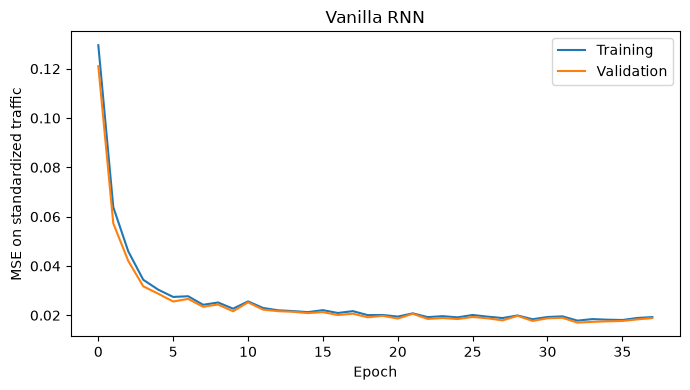

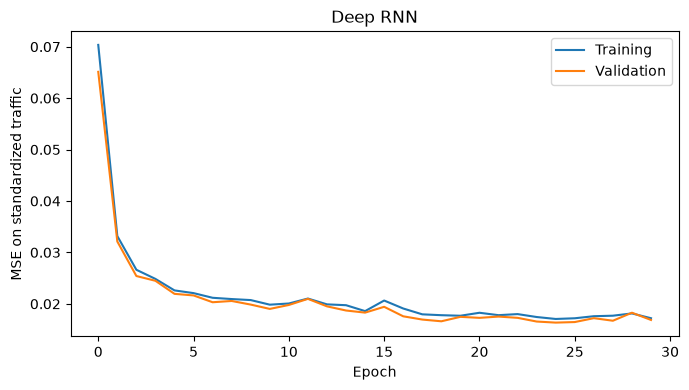

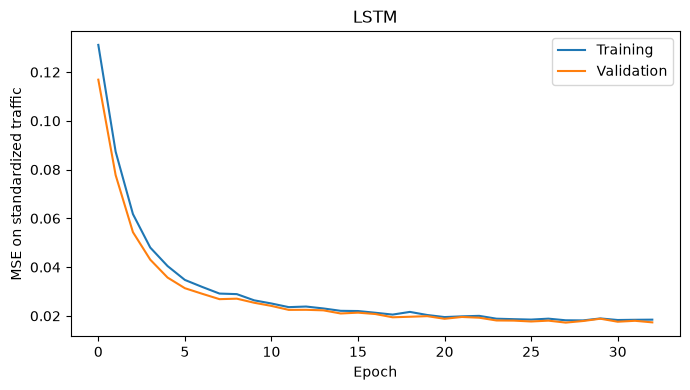

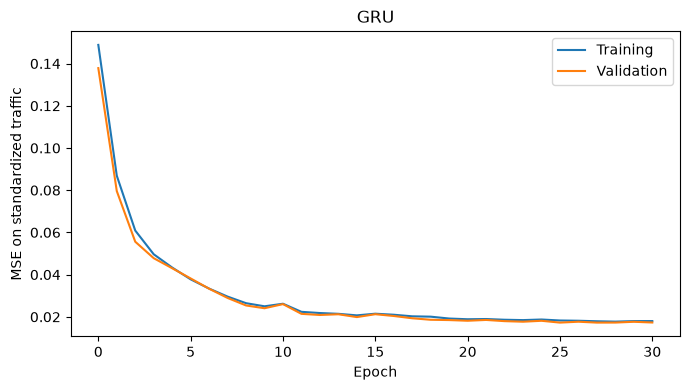

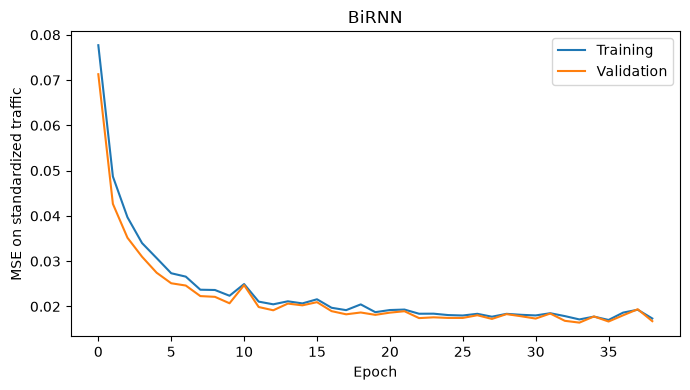

In [20]:
for name, history in histories.items():
    plt.figure(figsize=(7, 4))
    plt.plot(history["train"], label="Training")
    plt.plot(history["val"], label="Validation")
    plt.title(name)
    plt.xlabel("Epoch")
    plt.ylabel("MSE on standardized traffic")
    plt.legend()
    plt.tight_layout()
    plt.show()

#### 1.3.5 Inspect predictions

Plot the model with the lowest validation RMSE against actual traffic and the two baselines. A short plot helps reveal missed peaks that an average error can hide.

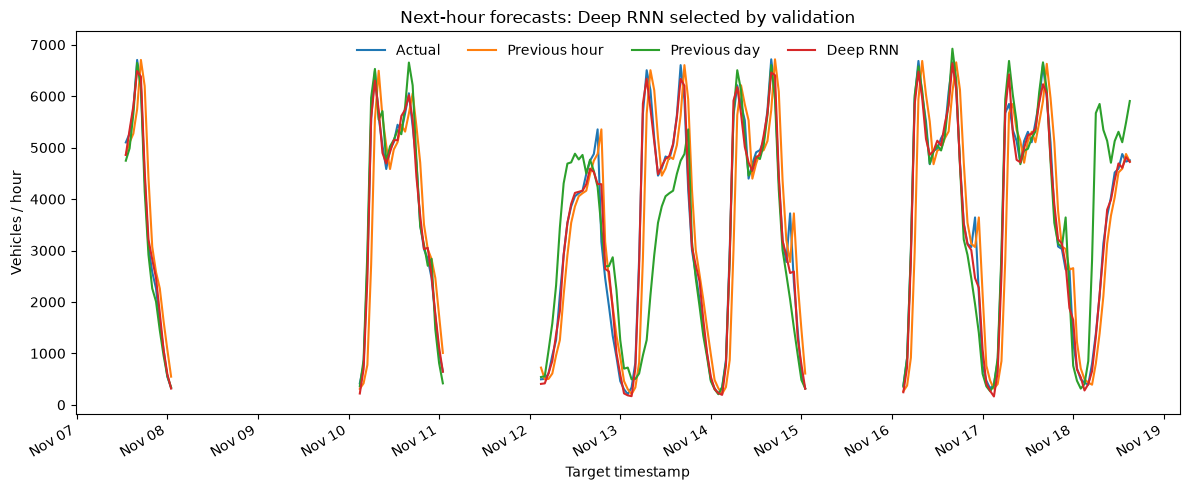

In [21]:
import matplotlib.dates as mdates

N_SHOW = 24 * 7 # show one week of predictions

# create a DataFrame to store the plots
plot_df = pd.DataFrame({"Actual": test_actual}, index=test_targets.index) 
for name in ["Previous hour", "Previous day", best_name]:
    plot_df[name] = test_predictions[name]

# Show gaps where incomplete histories excluded a forecast.
plot_df = plot_df.iloc[:N_SHOW].asfreq("h")

ax = plot_df.plot(figsize=(12, 5), linewidth=1.5, x_compat=True)
ax.set_title(f"Next-hour forecasts: {best_name} selected by validation")
ax.set_xlabel("Target timestamp")
ax.set_ylabel("Vehicles / hour")
ax.legend(loc="upper center", ncol=4, frameon=False)
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
plt.tight_layout()
plt.show()

### 1.4 Exercises and Discussions

Change one thing at a time and compare validation errors:

1. **Memory size:** try 32 versus 64 hidden units.
2. **Depth:** compare the one-layer and two-layer RNNs.
3. **Inputs:** compare traffic alone with traffic plus calendar features.

Keep the chronological splits and evaluation targets fixed.

## 2. Word-level language modeling 


A causal language model predicts the next word from preceding words. We compare **RNN, deep RNN, LSTM, and GRU** models using the same data and settings.

The dataset `time_machine.txt` can be downloaded from [Project Gutenberg](https://www.gutenberg.org/files/35/35-0.txt) or obtained from the course repository.

### 2.1 Text preprocessing

Read the dataset `time_machine.txt` saved in the subfolder  `Data`. The small functions below load the book, clean its text, and split it into words.

In [22]:
import copy
import math
import re
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
    torch.set_num_threads(2)
print("Device:", DEVICE)

Device: mps


#### 2.1.1 Load, clean, and tokenize

Remove the Project Gutenberg boundary lines. Keep lowercase letters and spaces, then split on spaces. Each token is one word.

In [23]:
def load_text(data_path):
    # Read the book as one string.
    with open(data_path, encoding="utf-8") as file:
        text = file.read()

    # Keep only the book content between the Gutenberg markers.
    text = text.split("*** START OF THE PROJECT GUTENBERG EBOOK 35 ***")[1]
    return text.split("*** END OF THE PROJECT GUTENBERG EBOOK 35 ***")[0]


def clean_text(text):
    # Convert to lowercase and replace punctuation, numbers, etc. with spaces.
    # Remove leading and trailing whitespace
    return re.sub("[^a-z]+", " ", text.lower()).strip() 


def tokenize(text):
    # Split on whitespace: each word becomes one token.
    return text.split()

DATA_PATH = "Data/time_machine.txt"
text = clean_text(load_text(DATA_PATH))
tokens = tokenize(text)

print("Words:", len(tokens))
print(tokens[:20])  # Inspect the first 20 tokens.

Words: 32895
['the', 'time', 'machine', 'an', 'invention', 'by', 'h', 'g', 'wells', 'contents', 'i', 'introduction', 'ii', 'the', 'machine', 'iii', 'the', 'time', 'traveller', 'returns']


#### 2.1.2 Vocabulary

Assign each word a numerical ID. Words that occur only once in the training text are grouped into `<unk>` (unknown). New validation or test words also map to `<unk>`.

This keeps the vocabulary manageable and gives the model training examples of unknown words. The vocabulary is built from **training text only** in Section 2.2.

In [24]:
class Vocab:
    def __init__(self, tokens, min_freq=2):
        # Count word occurrences and sort from most to least frequent.
        self.token_freqs = Counter(tokens).most_common()

        # Reserve ID 0 for rare or unseen words: <unk> means "unknown".
        self.idx_to_token = ["<unk>"]
        for token, count in self.token_freqs:
            if count >= min_freq:
                self.idx_to_token.append(token)

        # Create the reverse mapping: word --> numerical ID.
        self.token_to_idx = {
            token: i for i, token in enumerate(self.idx_to_token)
        }

    def __len__(self):
        # Allows len(vocab): number of vocabulary entries, including <unk>.
        return len(self.idx_to_token)

    def __getitem__(self, token):
        # Allows vocab["word"]: return its ID, or 0 if it is unknown.
        return self.token_to_idx.get(token, 0)

    def to_tokens(self, indices):
        # Convert a list of IDs back to words.
        return [self.idx_to_token[i] for i in indices]


def encode(tokens, vocab):
    # Convert a list of words into IDs that the model can use.
    return [vocab[token] for token in tokens]

### 2.2 Training, validation, and test data

Keep the text order: first 70% for training, next 15% for validation, and final 15% for testing. Build the vocabulary from training words, then use it to encode all three splits. These partitions stay fixed throughout training.

In [25]:
# Split in text order: 70% training, 15% validation, 15% testing.
train_end = int(0.70 * len(tokens))
val_end = int(0.85 * len(tokens))
train_tokens = tokens[:train_end]
val_tokens = tokens[train_end:val_end]
test_tokens = tokens[val_end:]

# Build the vocabulary from training words only to avoid information leakage.
vocab = Vocab(train_tokens)
VOCAB_SIZE = len(vocab)

# Use the same word-to-ID mapping for all splits.
# Rare or unseen words map to <unk> (ID 0).
train_corpus = encode(train_tokens, vocab)
val_corpus = encode(val_tokens, vocab)
test_corpus = encode(test_tokens, vocab)

print("Vocabulary size:", VOCAB_SIZE)
print("Train | validation | test words:",
      len(train_corpus), len(val_corpus), len(test_corpus))

# Check the conversion from words to IDs and back.
print("First word IDs:", train_corpus[:10])
print("Decoded words:", vocab.to_tokens(train_corpus[:10]))

# Report the fraction of words represented by <unk>.
print(
    f"Unknown words in validation | test: "
    f"{val_corpus.count(0)/len(val_corpus):.1%} | "
    f"{test_corpus.count(0)/len(test_corpus):.1%}"
)

Vocabulary size: 1726
Train | validation | test words: 23026 4934 4935
First word IDs: [1, 16, 49, 54, 1075, 40, 0, 0, 293, 1076]
Decoded words: ['the', 'time', 'machine', 'an', 'invention', 'by', '<unk>', '<unk>', 'wells', 'contents']
Unknown words in validation | test: 15.2% | 15.1%


#### 2.2.1 Input sequences and next-word targets

Each target sequence is the input shifted forward by one word.

```text
Input:   the   time     machine
Target:  time  machine  an
```

Use blocks of 10 words for a manageable example. Create blocks separately inside each split, omitting the final incomplete block. The hidden state starts fresh for each block. Shuffle training blocks, but keep validation and test blocks fixed.

In [26]:
NUM_TOKENS = 10

def make_dataset(corpus):
    ids = torch.tensor(corpus, dtype=torch.long)
    X, y = [], []
    for i in range(0, len(ids) - NUM_TOKENS, NUM_TOKENS):
        X.append(ids[i:i+NUM_TOKENS])
        y.append(ids[i+1:i+NUM_TOKENS+1])
    return TensorDataset(torch.stack(X), torch.stack(y))

train_ds = make_dataset(train_corpus)
val_ds = make_dataset(val_corpus)
test_ds = make_dataset(test_corpus)

BATCH_SIZE = 64
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE)
X, y = next(iter(train_loader))
print("Train | validation | test blocks:", len(train_ds), len(val_ds), len(test_ds))
print("Input shape | target shape:", X.shape, y.shape)

Train | validation | test blocks: 2302 493 493
Input shape | target shape: torch.Size([64, 10]) torch.Size([64, 10])


### 2.3 Recurrent models

Each model uses a built-in PyTorch layer and returns its sequence of outputs directly.

The language-model wrapper will use the output at every time step to predict the next word.

#### 2.3.1 RNN

Set `num_layers=1` for a vanilla RNN or `num_layers=2` for a deep RNN.

In [27]:
class RNN(nn.Module):
    def __init__(self, embed_size, num_hiddens, num_layers=1, dropout=0.0):
        super().__init__()
        self.num_hiddens = num_hiddens
        self.rnn = nn.RNN(embed_size, num_hiddens, num_layers=num_layers,
                          batch_first=True, dropout=dropout if num_layers > 1 else 0)

    def forward(self, x):
        out, h_n = self.rnn(x)
        return out

#### 2.3.2 LSTM

An LSTM also returns a cell state. For the wrapper, we need only its sequence of outputs.

In [28]:
class LSTM(nn.Module):
    def __init__(self, embed_size, num_hiddens, num_layers=1, dropout=0.0):
        super().__init__()
        self.num_hiddens = num_hiddens
        self.rnn = nn.LSTM(embed_size, num_hiddens, num_layers=num_layers,
                           batch_first=True, dropout=dropout if num_layers > 1 else 0)

    def forward(self, x):
        out, (h_n, c_n) = self.rnn(x)
        return out

#### 2.3.3 GRU

The calling pattern is the same as the vanilla RNN.

In [29]:
class GRU(nn.Module):
    def __init__(self, embed_size, num_hiddens, num_layers=1, dropout=0.0):
        super().__init__()
        self.num_hiddens = num_hiddens
        self.rnn = nn.GRU(embed_size, num_hiddens, num_layers=num_layers,
                          batch_first=True, dropout=dropout if num_layers > 1 else 0)

    def forward(self, x):
        out, h_n = self.rnn(x)
        return out

#### 2.3.4 Language-model wrapper

The wrapper has three parts:

1. **Embedding:** convert word IDs into learned vectors.
2. **Recurrent model:** represent the preceding words.
3. **Linear layer:** produce one next-word score for every vocabulary entry.

Dropout is used during training. The output shape is `(batch, sequence length, vocabulary size)`.

In [30]:
class LM(nn.Module):
    def __init__(self, cell, vocab_size, embed_size=64, dropout=0.2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.dropout = nn.Dropout(dropout)
        self.cell = cell
        self.output_proj = nn.Linear(cell.num_hiddens, vocab_size)

    def forward(self, X):
        vectors = self.dropout(self.embedding(X))
        out = self.cell(vectors)
        return self.output_proj(out)

#### 2.3.6 Models to compare

Compare vanilla RNN, deep RNN, LSTM, and GRU. Each uses the same embedding size, hidden size, optimizer, data, and stopping rule. The deep RNN has two layers; the other models have one layer. The wrapper and training code are shared.

In [31]:
EMBED_SIZE = 32
HIDDEN_SIZE = 64
MODEL_NAMES = ["RNN", "Deep RNN", "LSTM", "GRU"]

def make_model(name):
    if name == "RNN":
        cell = RNN(EMBED_SIZE, HIDDEN_SIZE)
    elif name == "Deep RNN":
        cell = RNN(EMBED_SIZE, HIDDEN_SIZE, num_layers=2)
    elif name == "LSTM":
        cell = LSTM(EMBED_SIZE, HIDDEN_SIZE)
    elif name == "GRU":
        cell = GRU(EMBED_SIZE, HIDDEN_SIZE)
    return LM(cell, VOCAB_SIZE, EMBED_SIZE).to(DEVICE)

### 2.4 Training and evaluation

Use **cross-entropy loss** to predict the correct next-word ID. Feed the raw scores into the loss function; do not apply softmax first.

Perplexity is the exponential of the average loss **per target word**:

$$
\mathrm{Perplexity} = \exp\!\left(\frac{\text{sum of next-word losses}}{\text{number of target words}}\right).
$$

Lower is better. Average the losses first, then take the exponential; do not average the batch perplexities. Validation selects the weights, and test perplexity reports their performance on held-out text.

In [32]:
def mean_cross_entropy(model, loader):
    model.eval()
    total = 0.0
    loss_fn = nn.CrossEntropyLoss(reduction="sum")
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(DEVICE), y.to(DEVICE)
            scores = model(X)
            total += loss_fn(scores.reshape(-1, VOCAB_SIZE), y.reshape(-1)).item()
    return total / (len(loader.dataset) * NUM_TOKENS)


def train_model(model, train_loader, val_loader, epochs=30, lr=0.003, patience=6):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    train_eval_loader = DataLoader(
        train_loader.dataset, batch_size=train_loader.batch_size, shuffle=False
    )
    history = {"train": [], "val": []}
    best_weights = copy.deepcopy(model.state_dict())
    best_val = float("inf")
    bad_epochs = 0

    for epoch in range(1, epochs + 1):
        model.train()
        for X, y in train_loader:
            X, y = X.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            scores = model(X)
            loss = loss_fn(scores.reshape(-1, VOCAB_SIZE), y.reshape(-1))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        train_loss = mean_cross_entropy(model, train_eval_loader)
        val_loss = mean_cross_entropy(model, val_loader)
        history["train"].append(train_loss)
        history["val"].append(val_loss)
        print(f"Epoch {epoch:02d} | Train perplexity={math.exp(train_loss):.2f} | Validation perplexity={math.exp(val_loss):.2f}")

        if val_loss < best_val - 1e-5:
            best_val = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print("Early stopping.")
                break

    model.load_state_dict(best_weights)
    return model, history

In [33]:
def perplexity(model, loader):
    return math.exp(mean_cross_entropy(model, loader))

#### 2.4.1 Word-frequency baseline

The baseline uses training-word frequencies and ignores the preceding text. Evaluate it on exactly the same targets as the recurrent model.

In [34]:
counts = torch.bincount(torch.tensor(train_corpus), minlength=VOCAB_SIZE).float()
word_probabilities = counts / counts.sum()

def frequency_perplexity(dataset):
    targets = dataset.tensors[1]
    mean_loss = -word_probabilities[targets].log().mean().item()
    return math.exp(mean_loss)

baseline_val = frequency_perplexity(val_ds)
baseline_test = frequency_perplexity(test_ds)
print(f"Baseline validation | test perplexity: {baseline_val:.2f} | {baseline_test:.2f}")

Baseline validation | test perplexity: 171.92 | 177.35


#### 2.4.2 Train and report results

Train every model for up to 30 epochs, stopping after six epochs without validation improvement. Restore each model's best validation weights before testing. Perplexity here includes `<unk>` targets and applies to this training-fitted vocabulary.

In [35]:
EPOCHS = 30
LR = 0.003
trained_models = {}
histories = {}
results = [{"Model": "Word frequency", "Validation perplexity": baseline_val,
            "Test perplexity": baseline_test}]

for name in MODEL_NAMES:
    print(f"\n{name}")
    torch.manual_seed(SEED)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                              generator=torch.Generator().manual_seed(SEED))
    lm_model = make_model(name)
    lm_model, history = train_model(lm_model, train_loader, val_loader, epochs=EPOCHS, lr=LR)
    trained_models[name] = lm_model
    histories[name] = history
    results.append({"Model": name, "Validation perplexity": perplexity(lm_model, val_loader),
                    "Test perplexity": perplexity(lm_model, test_loader)})

results_df = pd.DataFrame(results)
display(results_df.round(2))


RNN
Epoch 01 | Train perplexity=292.45 | Validation perplexity=193.65
Epoch 02 | Train perplexity=244.53 | Validation perplexity=166.34
Epoch 03 | Train perplexity=211.05 | Validation perplexity=148.17
Epoch 04 | Train perplexity=183.63 | Validation perplexity=133.78
Epoch 05 | Train perplexity=161.73 | Validation perplexity=122.09
Epoch 06 | Train perplexity=145.29 | Validation perplexity=113.93
Epoch 07 | Train perplexity=130.63 | Validation perplexity=108.50
Epoch 08 | Train perplexity=119.32 | Validation perplexity=106.29
Epoch 09 | Train perplexity=109.60 | Validation perplexity=102.38
Epoch 10 | Train perplexity=101.50 | Validation perplexity=99.66
Epoch 11 | Train perplexity=94.69 | Validation perplexity=98.54
Epoch 12 | Train perplexity=88.01 | Validation perplexity=96.68
Epoch 13 | Train perplexity=82.64 | Validation perplexity=95.92
Epoch 14 | Train perplexity=77.61 | Validation perplexity=97.03
Epoch 15 | Train perplexity=73.16 | Validation perplexity=95.38
Epoch 16 | Train

,Model,Validation perplexity,Test perplexity
0,Word frequency,171.92,177.35
1,RNN,94.99,96.69
2,Deep RNN,92.49,94.84
3,LSTM,93.83,94.55
4,GRU,103.04,105.89


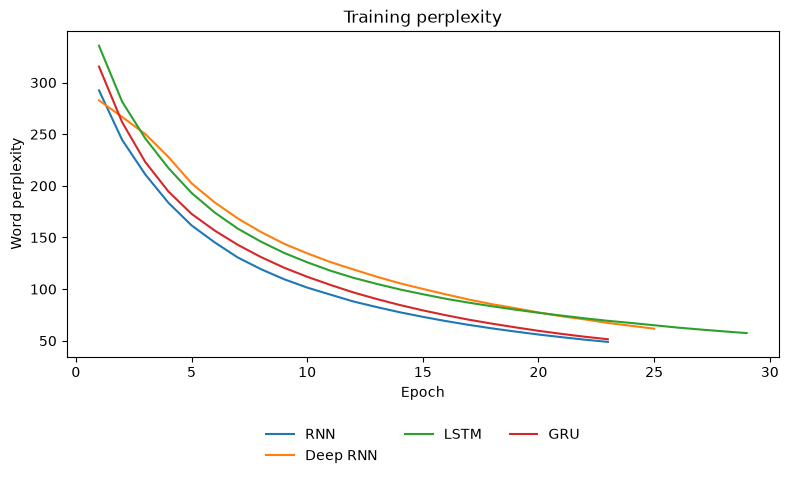

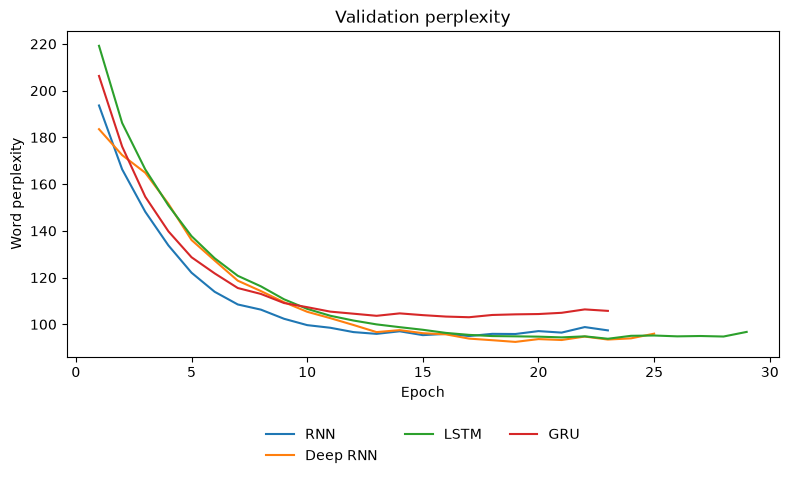

In [36]:
for split, label in [("train", "Training"), ("val", "Validation")]:
    plt.figure(figsize=(8, 5))
    for name, history in histories.items():
        epochs = range(1, len(history[split]) + 1)
        plt.plot(epochs, [math.exp(loss) for loss in history[split]], label=name)
    plt.xlabel("Epoch")
    plt.ylabel("Word perplexity")
    plt.title(f"{label} perplexity")
    plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
    plt.tight_layout()
    plt.show()

### 2.5 Generate text

Start with a prefix. The wrapper predicts the next-word scores from its most recent 10 words. Convert those scores to probabilities, sample one word, append it, and repeat.

Temperature controls the variation in sampling: smaller positive values favor high-probability words. A value of zero selects the highest-scoring word. A small model trained on one book is not expected to produce a coherent story.

Every model receives the same prefix, temperature, random seed, and number of generated words.

In [37]:
def sample_from_logits(scores, temperature=0.8):
    if temperature <= 0:
        return scores.argmax().item()
    probabilities = torch.softmax(scores / temperature, dim=-1)
    return torch.multinomial(probabilities, 1).item()


def generate(prefix, model, num_words=25, temperature=0.8):
    ids = encode(tokenize(clean_text(prefix)), vocab)
    if not ids:
        raise ValueError("Enter at least one word as a prefix.")
    model.eval()
    with torch.no_grad():
        for i in range(num_words):
            X = torch.tensor([ids[-NUM_TOKENS:]], device=DEVICE)
            scores = model(X)[0, -1]
            ids.append(sample_from_logits(scores, temperature))
    return " ".join(vocab.to_tokens(ids))

for name, model in trained_models.items():
    torch.manual_seed(SEED)
    print(name)
    print(generate("the time", model))
    print()

RNN
the time traveller came round the sun was were automatic <unk> my <unk> and <unk> incredulous for the loose of my mind and <unk> but i came

Deep RNN
the time traveller came round the sun i were automatic i saw a slow <unk> incredulous for the loose <unk> my <unk> and <unk> but a minute

LSTM
the time traveller i wonder not a queer the automatic table in the time traveller could for the loose <unk> my mind i felt a fair and

GRU
the time traveller i wonder to were not were automatic i saw a confident is could for the loose traveller of the future traveller but with the



The models learn familiar word patterns, but the generated sentences remain fragmented. During generation, each model uses its own predictions, so errors accumulate; lower test perplexity does not always mean more coherent text.

### 2.6 Experiments

1. Compare the models' validation and test perplexities. Does a more complex architecture always improve prediction?
2. Compare one-layer and two-layer RNNs.
3. Why does traffic forecasting use MSE, whereas next-word prediction uses cross-entropy?
4. Try temperatures 0 and 0.8. How does the generated text change?

Compare perplexities only when models use the same vocabulary and held-out text.